In [12]:
#Libraries Importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
#Loading and preprocessing the dataset
df = pd.read_csv("data/creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe().T)

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [4]:
#Checking for missing values
print('Missing values: ', df.isnull().sum().sum())
print('Duplicate values: ', df.duplicated().sum())

print("Unique Class Values:", df['Class'].unique())

Missing values:  0
Duplicate values:  1081
Unique Class Values: [0 1]


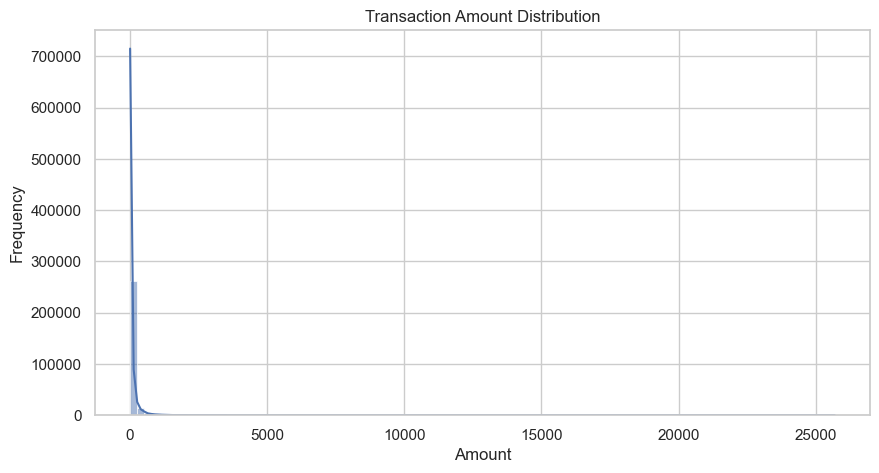

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64
AmountSkewness: 16.977724453761024


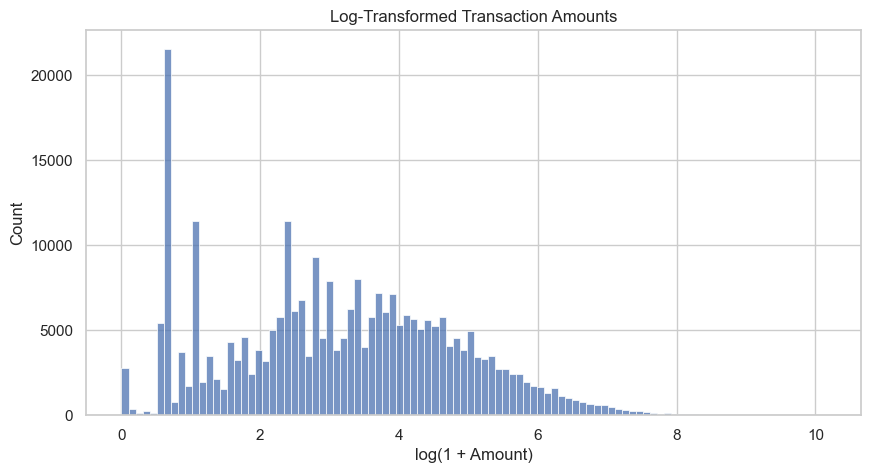

In [6]:
#Exploratory Data Analysis (EDA)
#1. Amount Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['Amount'], bins=100, kde=True)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()

print(df['Amount'].describe())
print("AmountSkewness:", df['Amount'].skew())

plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Amount"]), bins=100)
plt.title("Log-Transformed Transaction Amounts")
plt.xlabel("log(1 + Amount)")
plt.show()

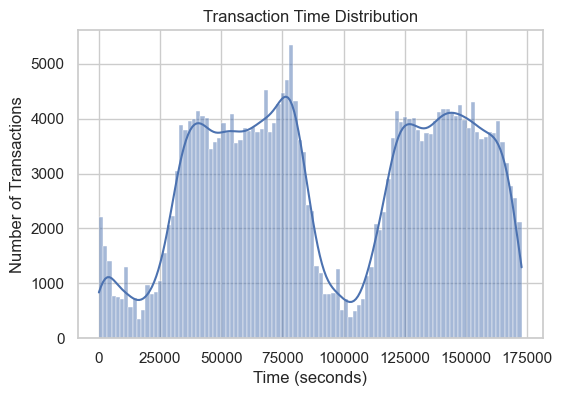

In [8]:
#2. Time Distribution
plt.figure(figsize=(6, 4))
sns.histplot(df['Time'], bins=100, kde=True)
plt.title('Transaction Time Distribution')
plt.xlabel('Time (seconds)')
plt.ylabel('Number of Transactions')
plt.show()

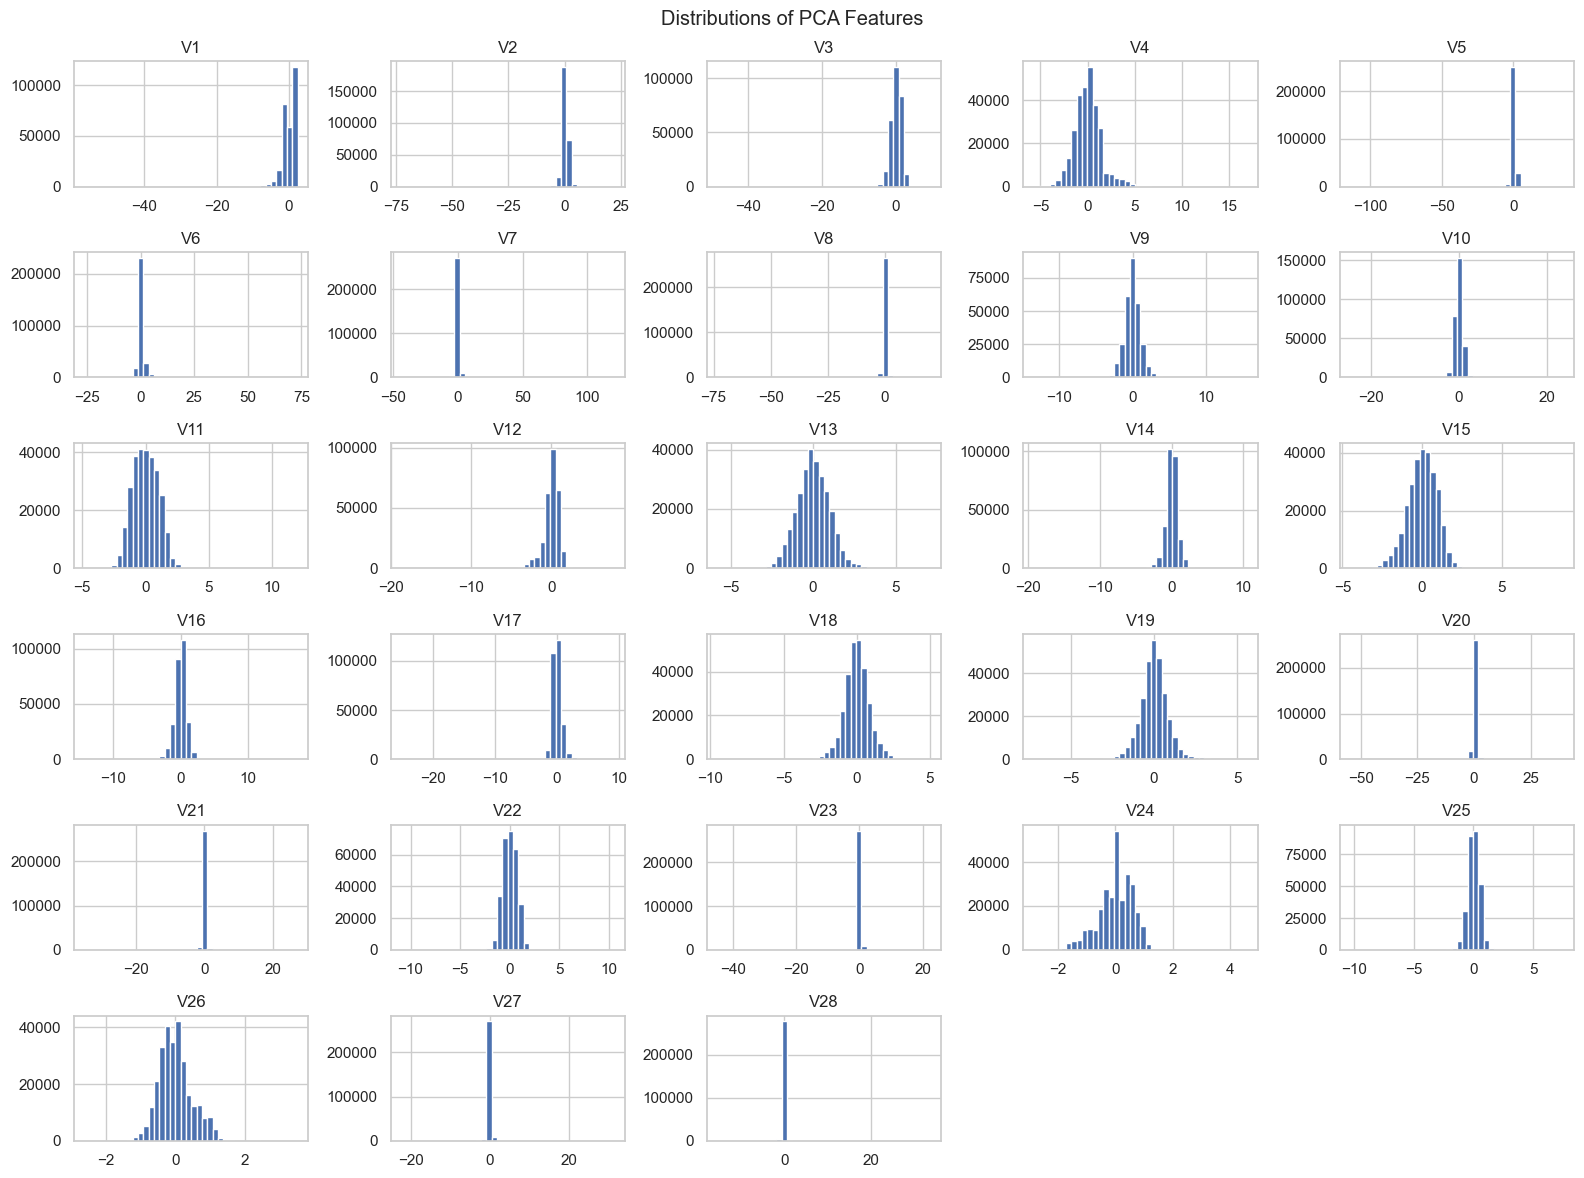

In [ ]:
#3. PCA Features Distribution
df[[f"V{i}" for i in range(1, 29)]].hist(
    figsize=(16, 12), bins=40
)
plt.suptitle("Distributions of PCA Features")
plt.tight_layout()
plt.show()

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


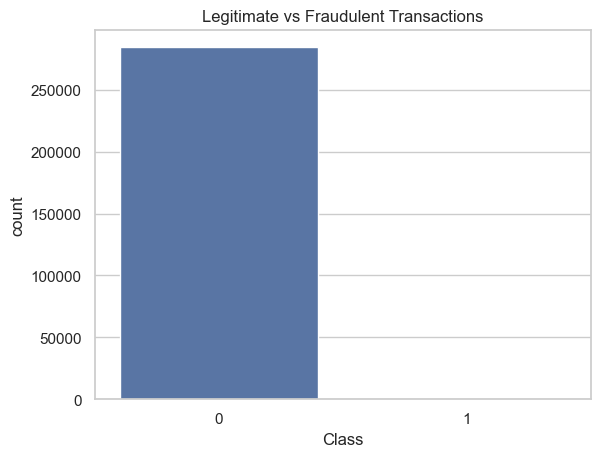

In [10]:
#4. Class Imbalance
print(df["Class"].value_counts())
print((df["Class"].value_counts(normalize=True) * 100).round(4))

sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.show()

In [11]:
#Seperate features from labels
y = df["Class"].copy()
X = df.drop("Class", axis=1)
print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print('Class in features:', "Class" in X.columns)

Features shape: (284807, 30)
Labels shape: (284807,)
Class in features: False


In [ ]:
#Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "Testing rows:", len(X_test))

Training rows: 227845 Testing rows: 56962


In [ ]:
#Scaling the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training matrix:", X_train_scaled.shape, "Testing matrix:", X_test_scaled.shape)

Training matrix: (227845, 30) Testing matrix: (56962, 30)


In [15]:
#Training the unsupervised Isolation Forest model
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Unsupervised training: features only
model.fit(X_train_scaled)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [16]:
#Predicting anomalies on the test set
# Isolation Forest convention:
#  1 = normal observation
# -1 = anomaly

raw_predictions = model.predict(X_test_scaled)

# Convert to:
# 0 = normal
# 1 = anomaly

y_pred = (raw_predictions == -1).astype(int)

print("Total test transactions:", len(y_pred))
print("Flagged anomalies:", int(y_pred.sum()))
print(
    "Percentage flagged:",
    round(y_pred.mean() * 100, 3),
    "%"
)

Total test transactions: 56962
Flagged anomalies: 2108
Percentage flagged: 3.701 %


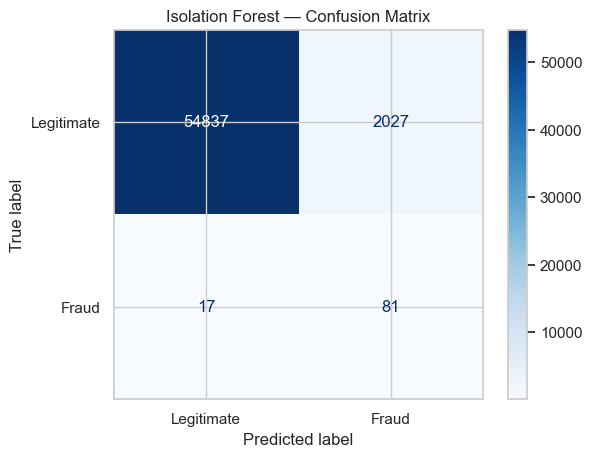

In [17]:
#Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Isolation Forest — Confusion Matrix")
plt.show()

In [18]:
#precision, recall, and F1-score
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

Precision: 0.0384
Recall:    0.8265
F1-score:  0.0734

Detailed report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98     56864
       Fraud       0.04      0.83      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.90      0.53     56962
weighted avg       1.00      0.96      0.98     56962



Average Precision: 0.1913


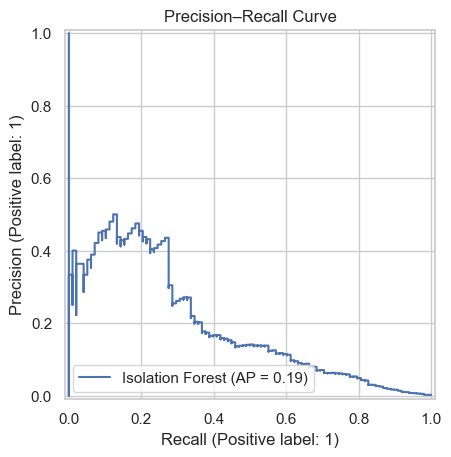

In [19]:
#Precision
# Higher values indicate greater anomaly
anomaly_scores = -model.decision_function(X_test_scaled)

ap = average_precision_score(
    y_test,
    anomaly_scores
)

print(f"Average Precision: {ap:.4f}")

PrecisionRecallDisplay.from_predictions(
    y_test,
    anomaly_scores,
    name="Isolation Forest"
)

plt.title("Precision–Recall Curve")
plt.show()

In [21]:
#Compare with One-Class SVM
from sklearn.svm import OneClassSVM

rng = np.random.default_rng(42)

sample_size = min(20000, len(X_train_scaled))

indices = rng.choice(
    len(X_train_scaled),
    size=sample_size,
    replace=False
)

X_svm_train = X_train_scaled[indices]

svm_model = OneClassSVM(
    kernel="rbf",
    nu=0.01,
    gamma="scale"
)

svm_model.fit(X_svm_train)

svm_raw = svm_model.predict(X_test_scaled)
svm_pred = (svm_raw == -1).astype(int)

print(
    classification_report(
        y_test,
        svm_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

svm_scores = -svm_model.decision_function(X_test_scaled)

print(
    "One-Class SVM Average Precision:",
    round(average_precision_score(y_test, svm_scores), 4)
)

              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.98     56864
       Fraud       0.04      0.76      0.08        98

    accuracy                           0.97     56962
   macro avg       0.52      0.86      0.53     56962
weighted avg       1.00      0.97      0.98     56962

One-Class SVM Average Precision: 0.0709


# Project Conclusion: Unsupervised Credit Card Fraud Detection

## Objective

The goal of this project was to identify potentially fraudulent credit card transactions using unsupervised machine learning without using fraud labels during model training.

## Dataset

Credit Card Fraud Detection – Kaggle: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

## Methodology

The Credit Card Fraud Detection dataset was explored and preprocessed. The `Class` column was separated from the model features, and the dataset was divided into training and testing sets. Numerical features were standardized using a scaler fitted only on the training data.

An Isolation Forest model was trained using transaction features without fraud labels. The model's predictions were subsequently evaluated using the held-out labels.

## Findings

The analysis of flagged transactions revealed [describe the actual patterns observed in transaction amounts, times, or PCA features].

The results indicate that [explain how effectively the model identified fraud and whether false positives were substantial].

## Limitations

Anomalies are not necessarily fraudulent transactions. The model may miss fraudulent activity that resembles normal transactions and may flag legitimate transactions that differ from typical patterns. Its performance also depends on the decision threshold and the features available.

## Future Improvements

Potential improvements include comparing additional unsupervised algorithms, evaluating different anomaly thresholds without using test labels for selection, and investigating autoencoders for nonlinear feature learning.

## Final Conclusion

This project demonstrates an unsupervised anomaly detection pipeline for credit card transactions. Fraud labels were excluded from model training and used only for evaluation. The experiment highlights both the potential and the limitations of unsupervised machine learning for rare-event detection in highly imbalanced datasets.